# Absenteeism Prediction : Exploratory Data Analysis and Preprocessing

**Prediction task:** given that an absence has been reported, predict whether it will be a **long absence (8 hours or more)**.

**Important scope note:** every row in this dataset is an absence event. The data can say how long an absence is likely to be. It cannot say whether an employee will be absent at all.

**Contents**
1. [Import packages](#1)
2. [Load the data](#2)
3. [Data-quality checks](#3)
4. [Target variable and rows excluded from modelling](#4)
5. [Univariate analysis](#5)
6. [Bivariate analysis: features vs long absence](#6)
7. [Multivariate analysis: correlations](#7)
8. [Employee structure and why the split must be grouped](#8)
9. [Outlier check](#9)
10. [Feature decisions](#10)
11. [Train/test split by employee](#11)
12. [Preprocessing pipeline demonstration](#12)
13. [Summary of findings and decisions](#13)

<a id='1'></a>
## 1. Import packages

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make the project's src/ package importable from inside notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

from src import config
from src.data_loader import load_raw_data, flag_rule_rows, build_modelling_dataset
from src.splitting import group_holdout_split
from src.preprocessing import build_preprocessor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    # Saved so the web app's EDA page can reuse verified figures later.
    plt.tight_layout()
    plt.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

<a id='2'></a>
## 2. Load the data

We load through `src/data_loader.py` so the notebook and the final application read the data identically. The loader also strips the trailing space in the raw header `'Work load Average/day '`.

In [2]:
raw = load_raw_data()
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (740, 21)


,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,Hit target,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239.554,97,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239.554,97,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239.554,97,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239.554,97,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239.554,97,0,1,2,1,0,1,90,172,30,2


In [3]:
raw.dtypes.to_frame('dtype').T

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,Hit target,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


<a id='3'></a>
## 3. Data-quality checks

In [4]:
# 3.1 Missing values
print("Total missing values:", int(raw.isna().sum().sum()))

# 3.2 Duplicate rows
dup_mask = raw.duplicated(keep=False)
print("Rows that are exact duplicates of another row (all copies):", int(dup_mask.sum()))
print("Redundant copies (duplicates beyond the first):", int(raw.duplicated().sum()))
print("Duplicates by employee (top 5):")
print(raw[raw.duplicated()].groupby("ID").size().sort_values(ascending=False).head(5).to_dict())

Total missing values: 0
Rows that are exact duplicates of another row (all copies): 60
Redundant copies (duplicates beyond the first): 34
Duplicates by employee (top 5):
{3: 16, 22: 5, 34: 5, 24: 2, 28: 2}


**Interpretation - duplicates.** The file has no date column, only month and weekday. The same employee can legitimately have two absences with the same month, weekday, reason and duration, which would appear as identical rows. We therefore **keep** duplicates rather than delete them. This is safe for evaluation because the grouped split (section 11) keeps all of an employee's rows on the same side, so duplicates can never leak between train and test.

In [5]:
# 3.3 Value-range / validity checks for coded columns
checks = {
    "Month of absence (valid 1-12)": raw[config.MONTH].value_counts().sort_index().to_dict(),
    "Day of the week": raw[config.DAY_OF_WEEK].value_counts().sort_index().to_dict(),
    "Seasons": raw[config.SEASONS].value_counts().sort_index().to_dict(),
    "Disciplinary failure": raw[config.DISCIPLINARY_FAILURE].value_counts().to_dict(),
    "Education": raw[config.EDUCATION].value_counts().sort_index().to_dict(),
}
for name, counts in checks.items():
    print(f"{name}: {counts}")

# 3.4 Is BMI just weight / height^2 ?
bmi_calc = raw[config.WEIGHT] / (raw[config.HEIGHT] / 100) ** 2
diff = (bmi_calc - raw[config.BMI]).abs()
print("\n|BMI(calculated) - BMI(recorded)|: mean", round(diff.mean(), 2), "| max", round(diff.max(), 2))

Month of absence (valid 1-12): {0: 3, 1: 50, 2: 72, 3: 87, 4: 53, 5: 64, 6: 54, 7: 67, 8: 54, 9: 53, 10: 71, 11: 63, 12: 49}
Day of the week: {2: 161, 3: 154, 4: 156, 5: 125, 6: 144}
Seasons: {1: 170, 2: 192, 3: 183, 4: 195}
Disciplinary failure: {0: 700, 1: 40}
Education: {1: 611, 2: 46, 3: 79, 4: 4}

|BMI(calculated) - BMI(recorded)|: mean 0.22 | max 1.33


**Interpretation - validity.** Month `0` is not a real month. It appears in 3 rows (handled in section 4). Day-of-week codes run 2 to 6 (five working days). The recorded BMI closely matches Weight / Height squared (differences are small, consistent with rounding of the recorded fields), so **BMI is largely redundant with Weight and Height**.

In [6]:
# 3.5 Do Seasons and Month agree cleanly?
pd.crosstab(raw[config.MONTH], raw[config.SEASONS])

Seasons,1,2,3,4
Month of absence,,,,
0,1,1,1,0
1,0,50,0,0
2,0,72,0,0
3,0,60,27,0
4,0,0,53,0
5,0,0,64,0
6,16,0,38,0
7,67,0,0,0
8,54,0,0,0


**Interpretation - Seasons.** Season codes are not one-to-one with months (for example month 3 appears under two different seasons). Seasons are largely derivable from the month, so they add little. The data dictionary is not in the file, so we do not rely on assumed season names.

In [7]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,740.0,18.02,11.02,1.00,9.00,18.00,28.00,36.00
Reason for absence,740.0,19.22,8.43,0.00,13.00,23.00,26.00,28.00
Month of absence,740.0,6.32,3.44,0.00,3.00,6.00,9.00,12.00
Day of the week,740.0,3.91,1.42,2.00,3.00,4.00,5.00,6.00
Seasons,740.0,2.54,1.11,1.00,2.00,3.00,4.00,4.00
Transportation expense,740.0,221.33,66.95,118.00,179.00,225.00,260.00,388.00
Distance from Residence to Work,740.0,29.63,14.84,5.00,16.00,26.00,50.00,52.00
Service time,740.0,12.55,4.38,1.00,9.00,13.00,16.00,29.00
Age,740.0,36.45,6.48,27.00,31.00,37.00,40.00,58.00
Work load Average/day,740.0,271.49,39.06,205.92,244.39,264.25,294.22,378.88


<a id='4'></a>
## 4. Target variable and rows excluded from modelling

Mean: 6.92 | Median: 3.0 | Max: 120 | Skewness: 5.72


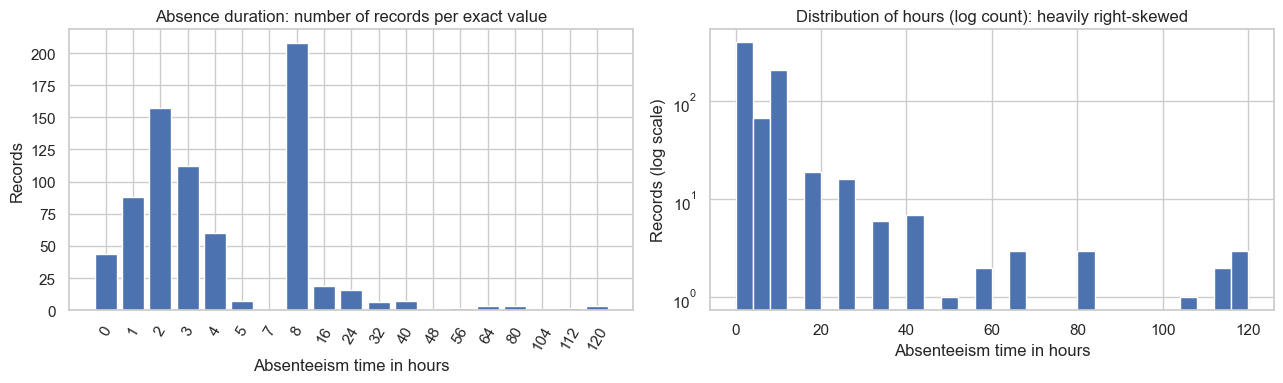

In [8]:
hours = raw[config.RAW_TARGET_COLUMN]
print("Mean:", round(hours.mean(), 2), "| Median:", hours.median(), "| Max:", hours.max(), "| Skewness:", round(hours.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = hours.value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values, color="#4C72B0")
axes[0].set_title("Absence duration: number of records per exact value")
axes[0].set_xlabel("Absenteeism time in hours"); axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=60)

axes[1].hist(hours, bins=30, color="#4C72B0")
axes[1].set_yscale("log")
axes[1].set_title("Distribution of hours (log count): heavily right-skewed")
axes[1].set_xlabel("Absenteeism time in hours"); axes[1].set_ylabel("Records (log scale)")
save_fig("01_target_distribution")

**Interpretation - why classification with an 8-hour threshold.**
* The hours are extremely skewed (mean about 6.9, median 3, maximum 120). A regression model's error would be dominated by a few very long absences.
* There is a natural break in the data: values run 0 to 5, then a single record at 7, then **208 records at exactly 8** (one full working day), then rare larger values. A threshold of 8 hours therefore separates "within a day" from "a day or more" without cherry-picking a number.

In [9]:
long_flag = hours >= config.LONG_ABSENCE_THRESHOLD_HOURS
print(f"Long absences (>= 8h): {long_flag.sum()} of {len(raw)}  ({long_flag.mean():.1%})")
print("Records between 5 and 8 hours exclusive of both:", int(((hours > 5) & (hours < 8)).sum()), "(only the single 7-hour record)")

Long absences (>= 8h): 271 of 740  (36.6%)
Records between 5 and 8 hours exclusive of both: 1 (only the single 7-hour record)


### 4.1 Rows whose outcome is fixed by a rule

In [10]:
reason_zero = raw[config.REASON] == 0
disc_one = raw[config.DISCIPLINARY_FAILURE] == 1
rule = flag_rule_rows(raw)

summary = pd.DataFrame({
    "rows": [reason_zero.sum(), disc_one.sum(), (reason_zero & disc_one).sum(), rule.sum(), (raw[config.MONTH] == 0).sum()],
    "rows with 0 hours": [
        (hours[reason_zero] == 0).sum(), (hours[disc_one] == 0).sum(),
        (hours[reason_zero & disc_one] == 0).sum(), (hours[rule] == 0).sum(),
        (hours[raw[config.MONTH] == 0] == 0).sum()],
}, index=["Reason for absence == 0", "Disciplinary failure == 1", "Both", "Either (union)", "Month == 0"])
summary["share with 0 hours"] = (summary["rows with 0 hours"] / summary["rows"]).round(2)
display(summary)
print("Zero-hour rows NOT covered by the rule:", int(((hours == 0) & ~rule).sum()))

,rows,rows with 0 hours,share with 0 hours
Reason for absence == 0,43,43,1.0
Disciplinary failure == 1,40,40,1.0
Both,40,40,1.0
Either (union),43,43,1.0
Month == 0,3,3,1.0


Zero-hour rows NOT covered by the rule: 1


**Decision - exclude the 43 rule rows from modelling.** Every row with `Reason for absence = 0` or `Disciplinary failure = 1` has 0 hours (100%). Together they account for 43 of the 44 zero-hour rows, and the three `Month = 0` rows are among them. A model would score well by memorising this rule without learning anything about genuine absences. This is a form of leakage: the information describes the record's status, not a pattern that predicts duration.
The rule is documented in `src/data_loader.py::flag_rule_rows` and the application will treat these cases as outside the model's scope. What the codes actually mean is **not stated in the file**, so we describe them only by their observed behaviour.

Modelling dataset: (697, 15) | employees: 33
{'short (<8h)': 426, 'long (>=8h)': 271} -> long share 38.9%


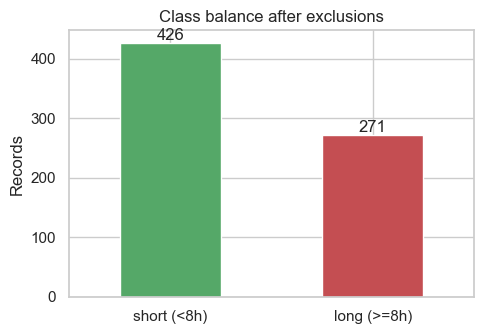

In [11]:
model_df = build_modelling_dataset(raw)
print("Modelling dataset:", model_df.shape, "| employees:", model_df[config.GROUP_COLUMN].nunique())

balance = model_df[config.TARGET_COLUMN].value_counts().rename({0: "short (<8h)", 1: "long (>=8h)"})
print(balance.to_dict(), f"-> long share {model_df[config.TARGET_COLUMN].mean():.1%}")

ax = balance.plot.bar(color=["#55A868", "#C44E52"], rot=0, figsize=(5, 3.5))
ax.set_title("Class balance after exclusions"); ax.set_ylabel("Records"); ax.set_xlabel("")
for i, v in enumerate(balance.values): ax.text(i, v + 5, str(v), ha="center")
save_fig("02_class_balance")

**Interpretation - class balance.** 697 records remain; about 39% are long absences. This is only mild imbalance, so no resampling is needed. Accuracy alone is still a weak metric (always predicting "short" scores about 61%), which is why Phase 3 will also use recall, F1 and PR-AUC for the long class.

<a id='5'></a>
## 5. Univariate analysis

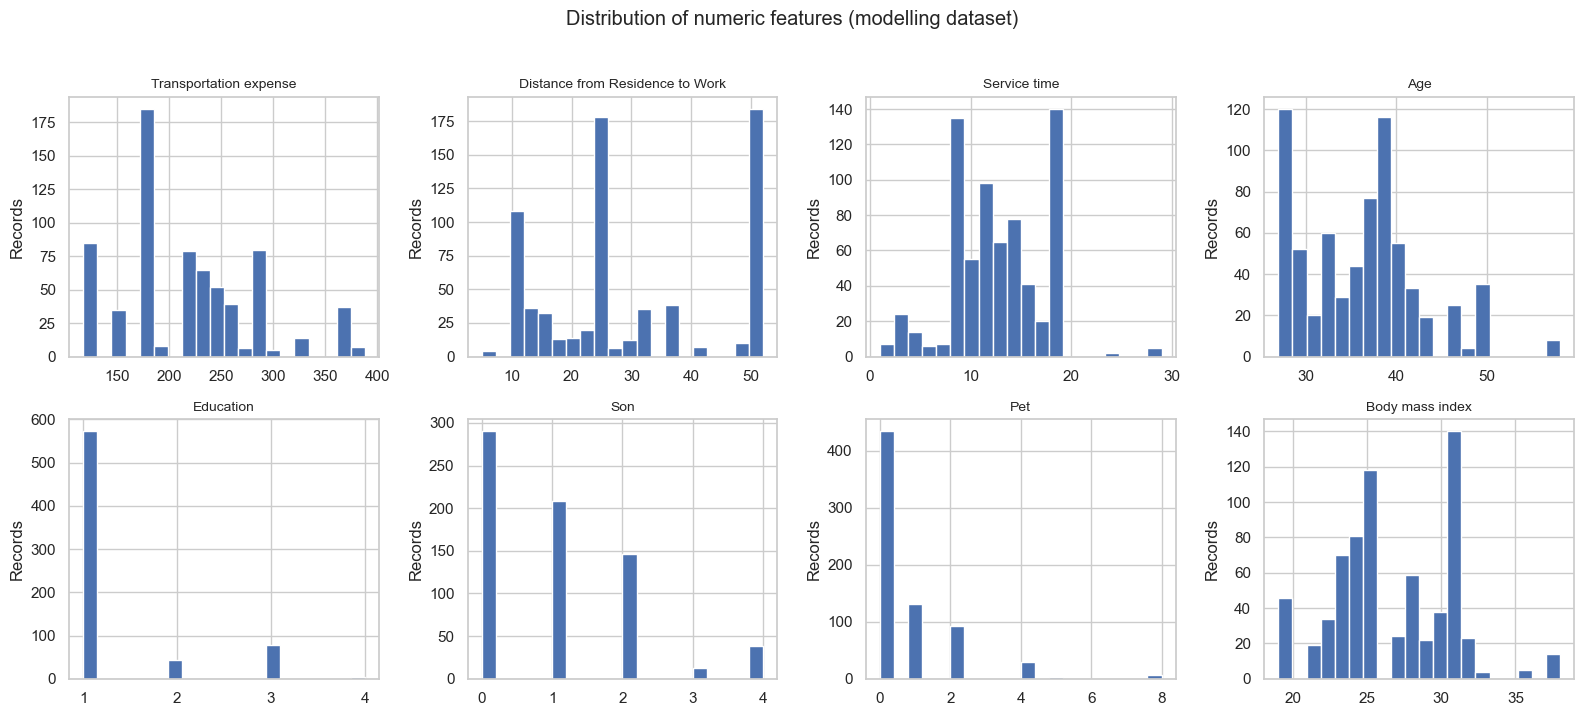

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), config.NUMERIC_FEATURES):
    ax.hist(model_df[col], bins=20, color="#4C72B0")
    ax.set_title(col, fontsize=10); ax.set_ylabel("Records")
fig.suptitle("Distribution of numeric features (modelling dataset)", y=1.02)
save_fig("03_numeric_distributions")

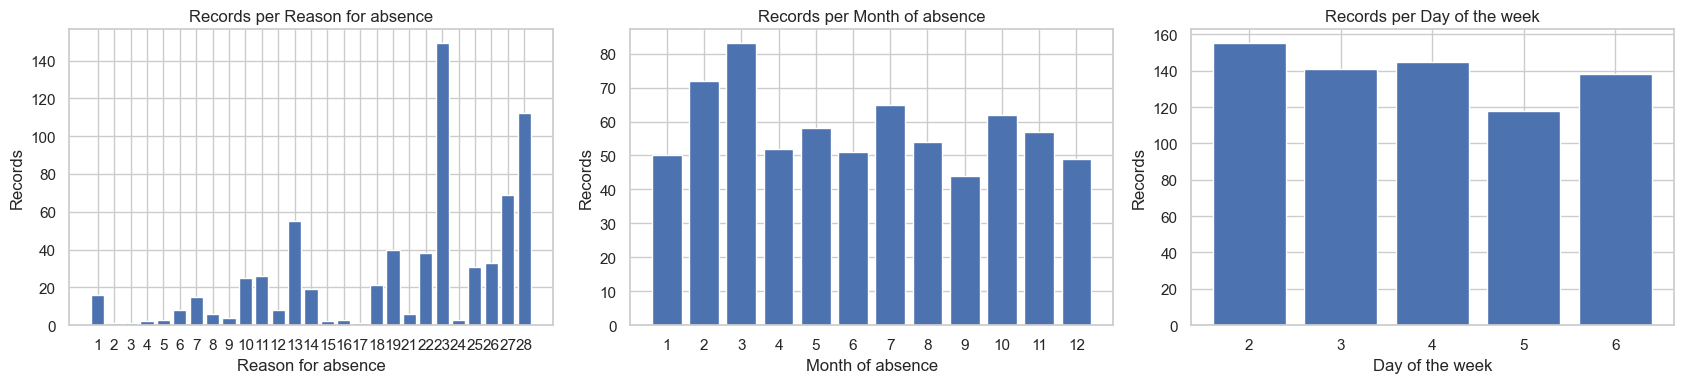

Reason codes with fewer than 10 records:
{2: 1, 3: 1, 4: 2, 5: 3, 6: 8, 8: 6, 9: 4, 12: 8, 15: 2, 16: 3, 17: 1, 21: 6, 24: 3}


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, config.CATEGORICAL_FEATURES):
    vc = model_df[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#4C72B0")
    ax.set_title(f"Records per {col}"); ax.set_xlabel(col); ax.set_ylabel("Records")
save_fig("04_categorical_counts")

print("Reason codes with fewer than 10 records:")
rc = model_df[config.REASON].value_counts()
print(rc[rc < config.MIN_CATEGORY_FREQUENCY].sort_index().to_dict())

**Interpretation.**
* `Reason for absence` is very uneven: a few codes (23, 28, 27, 13) dominate, while 13 codes have fewer than 10 records. A one-hot column built from 1-3 records cannot be learned reliably, so rare codes will be pooled into one "infrequent" group inside the preprocessor (`min_frequency=10`).
* `Education` is dominated by level 1 (572 of 697 records); level 4 has just 4 records.
* `Social smoker` and `Pet` are heavily skewed to 0; the other numeric columns are broadly spread with no impossible values.

<a id='6'></a>
## 6. Bivariate analysis: features vs long absence

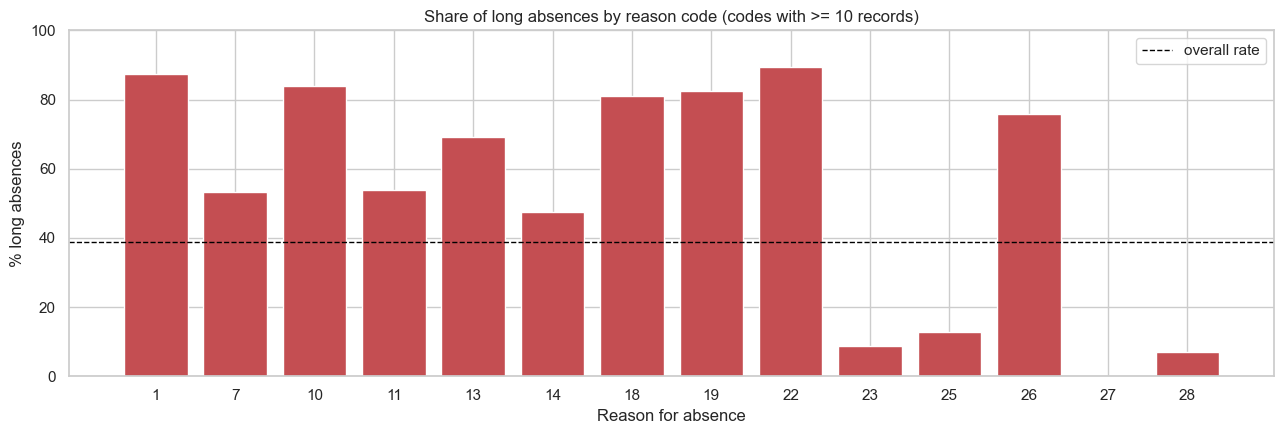

Reason for absence     1      7      10     11     13     14     18     19     22      23     25     26    27      28
mean                 0.88   0.53   0.84   0.54   0.69   0.47   0.81   0.82   0.89    0.09   0.13   0.76   0.0    0.07
count               16.00  15.00  25.00  26.00  55.00  19.00  21.00  40.00  38.00  149.00  31.00  33.00  69.0  112.00


In [14]:
def long_rate_chart(col, title, ax, min_n=1):
    g = model_df.groupby(col)[config.TARGET_COLUMN].agg(["mean", "count"])
    g = g[g["count"] >= min_n]
    ax.bar(g.index.astype(str), g["mean"] * 100, color="#C44E52")
    ax.axhline(model_df[config.TARGET_COLUMN].mean() * 100, color="black", ls="--", lw=1, label="overall rate")
    ax.set_title(title); ax.set_xlabel(col); ax.set_ylabel("% long absences"); ax.set_ylim(0, 100)
    ax.legend()
    return g

fig, ax = plt.subplots(figsize=(13, 4.5))
g = long_rate_chart(config.REASON, "Share of long absences by reason code (codes with >= 10 records)", ax, min_n=10)
save_fig("05_long_rate_by_reason")
print(g.round(2).T.to_string())

**Interpretation - Reason for absence is the dominant signal.** Some reason codes are almost always short (for example 23: 9%, 28: 7%, 25: 13%, 27: 0% long) while others are mostly long (1: 88%, 22: 89%, 10: 84%, 19: 82%, 18: 81%). Expect the model's performance to be driven largely by this column. That is a legitimate finding, not an error, but it also means that **`Reason for absence` must be an input the user supplies**, and we should report how much performance depends on it in Phase 3.

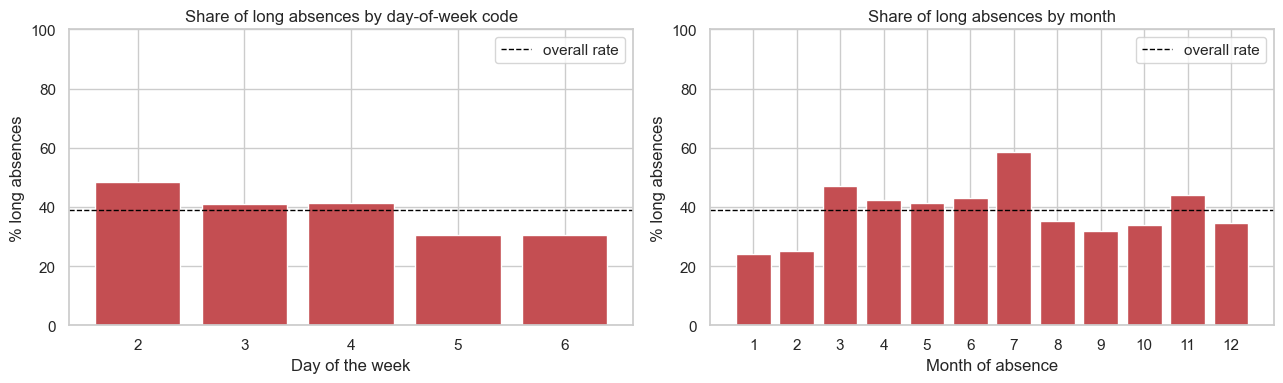

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
long_rate_chart(config.DAY_OF_WEEK, "Share of long absences by day-of-week code", axes[0])
long_rate_chart(config.MONTH, "Share of long absences by month", axes[1])
save_fig("06_long_rate_by_day_month")

**Interpretation.** Day code 2 has the highest long-absence share (about 48%), declining to about 30% for code 6. Month-to-month variation is moderate (each month has only about 44-83 records, so individual bars are noisy). These are descriptive differences, not proof of a causal effect.

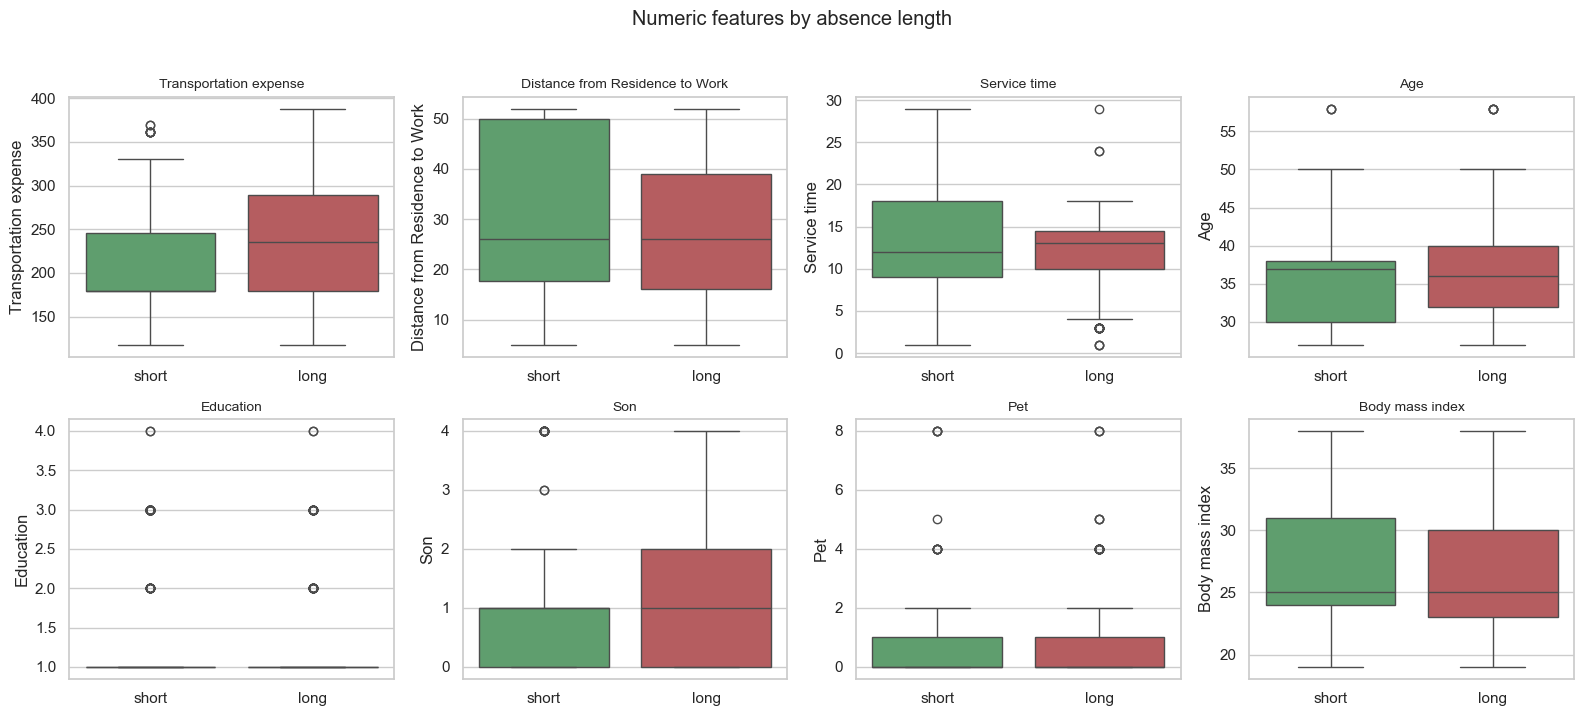

long_absence                          0       1
Transportation expense           205.85  241.65
Distance from Residence to Work   30.34   29.01
Service time                      12.77   12.20
Age                               36.27   36.24
Education                          1.31    1.28
Son                                0.84    1.24
Pet                                0.65    0.86
Body mass index                   26.54   26.64

Social drinker {0: 33.0, 1: 43.0} % long; n = {1: 391, 0: 306}
Social smoker {0: 38.0, 1: 54.0} % long; n = {0: 651, 1: 46}


In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), config.NUMERIC_FEATURES):
    sns.boxplot(data=model_df, x=config.TARGET_COLUMN, y=col, hue=config.TARGET_COLUMN, legend=False, ax=ax, palette=["#55A868", "#C44E52"])
    ax.set_xticks([0, 1]); ax.set_xticklabels(["short", "long"]); ax.set_xlabel(""); ax.set_title(col, fontsize=10)
fig.suptitle("Numeric features by absence length", y=1.02)
save_fig("07_numeric_by_target")

print(model_df.groupby(config.TARGET_COLUMN)[config.NUMERIC_FEATURES].mean().round(2).T)
print()
for col in config.BINARY_FEATURES:
    print(col, (model_df.groupby(col)[config.TARGET_COLUMN].mean() * 100).round(0).to_dict(), "% long; n =", model_df[col].value_counts().to_dict())

**Interpretation - and a caution.** Mean `Transportation expense` is higher for long absences (about 242 vs 206), and `Son` is higher too (about 1.2 vs 0.8). However, these personal attributes **do not change within an employee**, so such differences mostly reflect *which employees* have many long absences, not an effect of the attribute itself. Social smokers show a higher long-absence share (about 54% vs 38%) but are a small group (46 records). These are correlations in 33 people and must not be presented as causes.

<a id='7'></a>
## 7. Multivariate analysis: correlations

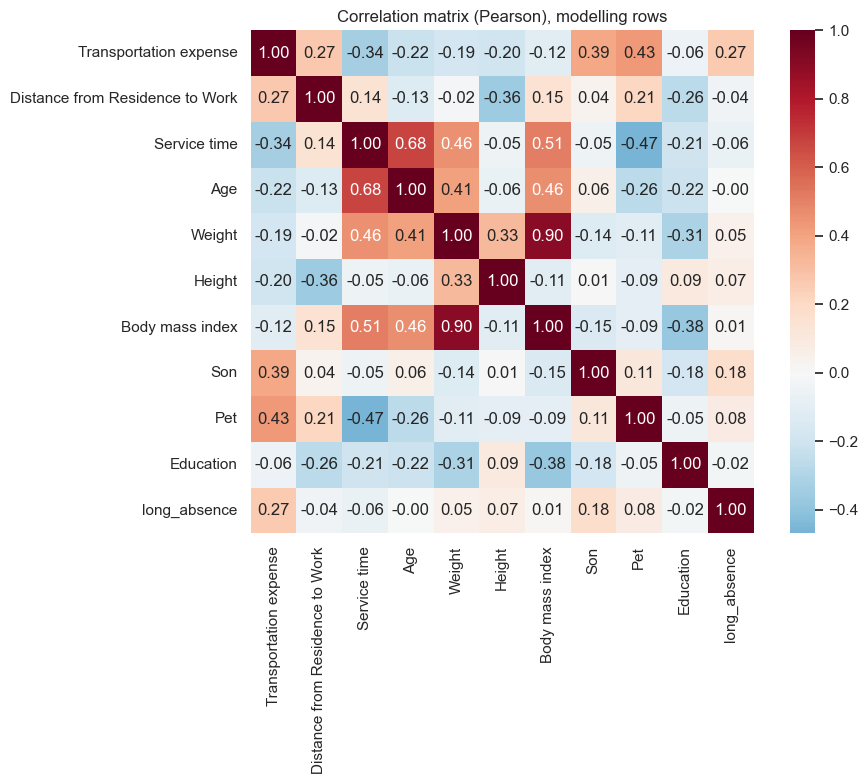

In [17]:
corr_cols = [config.TRANSPORT_EXPENSE, config.DISTANCE, config.SERVICE_TIME, config.AGE,
             config.WEIGHT, config.HEIGHT, config.BMI, config.SON, config.PET, config.EDUCATION,
             config.TARGET_COLUMN]
corr_df = raw.loc[~flag_rule_rows(raw)].copy()
corr_df[config.TARGET_COLUMN] = (corr_df[config.RAW_TARGET_COLUMN] >= config.LONG_ABSENCE_THRESHOLD_HOURS).astype(int)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation matrix (Pearson), modelling rows")
save_fig("08_correlation_heatmap")

**Interpretation.** Weight and BMI are strongly correlated (about 0.90), as expected from the BMI formula. Keeping both would give linear models redundant inputs, so we keep **BMI only** and drop Weight and Height (this also reduces the number of sensitive personal attributes). Correlation with the target is modest everywhere: the largest are `Transportation expense` (about 0.27) and `Son` (about 0.18), both fixed per employee (see section 8); the other numeric features are close to 0. Pearson correlation with a binary target is only a rough guide.

<a id='8'></a>
## 8. Employee structure and why the split must be grouped

Employees: 33 | rows per employee: min 2 max 112
Top 3 employees account for 35% of all rows
Employees whose personal attributes change between rows: 0
Distinct personal-attribute profiles: 33 (vs 33 employees)


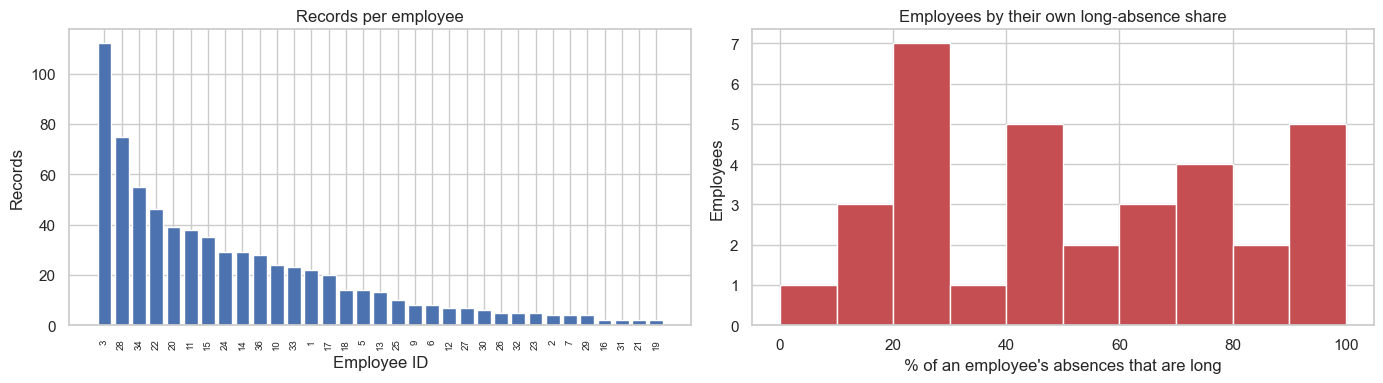

In [18]:
per_emp = model_df.groupby(config.GROUP_COLUMN)[config.TARGET_COLUMN].agg(rows="count", long_rate="mean").sort_values("rows", ascending=False)
print("Employees:", len(per_emp), "| rows per employee: min", per_emp.rows.min(), "max", per_emp.rows.max())
print(f"Top 3 employees account for {per_emp.rows.head(3).sum() / per_emp.rows.sum():.0%} of all rows")

employee_attrs = [config.DISTANCE, config.SERVICE_TIME, config.AGE, config.EDUCATION, config.SON,
                  config.SOCIAL_DRINKER, config.BMI, config.TRANSPORT_EXPENSE, config.SOCIAL_SMOKER, config.PET]
changing = (model_df.groupby(config.GROUP_COLUMN)[employee_attrs].nunique() > 1).any(axis=1).sum()
unique_profiles = model_df[employee_attrs].drop_duplicates().shape[0]
print("Employees whose personal attributes change between rows:", int(changing))
print("Distinct personal-attribute profiles:", unique_profiles, "(vs", len(per_emp), "employees)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(per_emp.index.astype(str), per_emp.rows, color="#4C72B0")
axes[0].set_title("Records per employee"); axes[0].set_xlabel("Employee ID"); axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[1].hist(per_emp.long_rate * 100, bins=10, color="#C44E52")
axes[1].set_title("Employees by their own long-absence share"); axes[1].set_xlabel("% of an employee's absences that are long"); axes[1].set_ylabel("Employees")
save_fig("09_employee_structure")

**Interpretation - the key design decision.**
* Each employee has between 2 and 112 records, and the three largest account for about 35% of the data.
* Personal attributes are constant per employee, so the set of attributes acts as a **fingerprint**: a model can learn "this age + distance + BMI means employee X, who usually has long absences".
* Employees differ widely in their own long-absence share (see right chart).

If we split rows randomly, the same employees appear in train and test, and the model is partly graded on people it has already seen. Scores would be optimistic. The honest question is *how well does the model do for an employee it has never seen*, so we split and cross-validate **by employee**. In Phase 3 we will also run a random split to quantify how misleading it would have been.

<a id='9'></a>
## 9. Outlier check

In [19]:
rows = []
for col in config.NUMERIC_FEATURES:
    q1, q3 = model_df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": col, "min": model_df[col].min(), "max": model_df[col].max(),
                 "IQR-flagged rows": int(((model_df[col] < low) | (model_df[col] > high)).sum())})
pd.DataFrame(rows).set_index("feature")

,min,max,IQR-flagged rows
feature,,,
Transportation expense,118,388,2
Distance from Residence to Work,5,52,0
Service time,1,29,5
Age,27,58,8
Education,1,4,125
Son,0,4,0
Pet,0,8,40
Body mass index,19,38,0


**Decision - keep all values, remove none.** The IQR rule flags few rows for most features. `Education` (125) and `Pet` (40) are flagged only because most values are 0 or 1, so a 3 or 4 looks unusual statistically even though it is a valid category or count. No value is physically impossible (for example ages 27-58). With 697 rows, deleting records would discard real information. `StandardScaler` does not clip values, and the tree-based models are not sensitive to extremes, so extreme values are tolerated. The target's long tail is handled by the 8-hour threshold rather than by removing rows.

<a id='10'></a>
## 10. Feature decisions

In [20]:
kept = pd.DataFrame({"feature": config.FEATURE_COLUMNS,
                     "treatment": ["one-hot"] * len(config.CATEGORICAL_FEATURES)
                                  + ["passthrough (0/1)"] * len(config.BINARY_FEATURES)
                                  + ["standardise"] * len(config.NUMERIC_FEATURES)})
display(kept)
print("Columns NOT used as model features:")
pd.Series(config.EXCLUDED_FEATURES, name="reason").to_frame()

,feature,treatment
0,Reason for absence,one-hot
1,Month of absence,one-hot
2,Day of the week,one-hot
3,Social drinker,passthrough (0/1)
4,Social smoker,passthrough (0/1)
5,Transportation expense,standardise
6,Distance from Residence to Work,standardise
7,Service time,standardise
8,Age,standardise
9,Education,standardise


Columns NOT used as model features:


,reason
ID,Employee identifier: used only for grouped spl...
Absenteeism time in hours,Source of the target; using it would be direct...
Disciplinary failure,Constant (always 0) once the 43 rule rows are ...
Seasons,Redundant with Month of absence (derivable fro...
Weight,Highly correlated with BMI (r=0.90); BMI kept ...
Height,Summarised by BMI; fewer sensitive raw attribu...
Work load Average/day,Company-level monthly figure that identifies t...
Hit target,Same as above (period identifier). Tested by a...


**Notes on the two period features.** `Work load Average/day` and `Hit target` take only 37 distinct combinations in the data, one per month-and-year period, so they effectively tell the model *when* a record occurred, and they are not something a person reporting one absence would know. We exclude them from the default model, and **Phase 3 will test the model with and without them** so the decision is backed by evidence, not assumed.
No feature engineering is added at this stage: with so few rows, extra derived features add risk of overfitting and would complicate the web form. Alternatives (for example cyclic encoding of month) can be tested in Phase 3 if justified.

<a id='11'></a>
## 11. Train/test split by employee

In [24]:
train_df, test_df = group_holdout_split(model_df)

split_summary = pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "employees": [train_df[config.GROUP_COLUMN].nunique(), test_df[config.GROUP_COLUMN].nunique()],
    "long-absence share": [train_df[config.TARGET_COLUMN].mean().round(3), test_df[config.TARGET_COLUMN].mean().round(3)],
}, index=["train", "test (held out)"])
display(split_summary)

overlap = set(train_df[config.GROUP_COLUMN]) & set(test_df[config.GROUP_COLUMN])
print("Employees in both train and test:", len(overlap), "(must be 0)")
print("Held-out test employees:", sorted(test_df[config.GROUP_COLUMN].unique()))

,rows,employees,long-absence share
train,575,27,0.390
test (held out),122,6,0.385


Employees in both train and test: 0 (must be 0)
Held-out test employees: [np.int64(13), np.int64(16), np.int64(20), np.int64(27), np.int64(30), np.int64(34)]


**Interpretation.** The test set contains whole employees the model never sees in training, with a similar long-absence share to the training set (about 39%). The test set is small (6 employees), so a single test score will be noisy. For this reason model *selection* in Phase 3 will use repeated cross-validation grouped by employee on the training set, and the test set will be used once, at the end. The test set must not be used to choose features, thresholds or hyperparameters.

<a id='12'></a>
## 12. Preprocessing pipeline demonstration

In [22]:
preprocessor = build_preprocessor()

# fit() learns the one-hot categories and the scaling means/stds from TRAINING rows only
preprocessor.fit(train_df[config.FEATURE_COLUMNS])

X_train_t = preprocessor.transform(train_df[config.FEATURE_COLUMNS])
X_test_t = preprocessor.transform(test_df[config.FEATURE_COLUMNS])   # re-uses training statistics
names = preprocessor.get_feature_names_out()

print("Input columns:", len(config.FEATURE_COLUMNS), "-> model columns:", len(names))
print("Train matrix:", X_train_t.shape, "| Test matrix:", X_test_t.shape)
print("Any NaN after transform:", bool(np.isnan(X_train_t).any() or np.isnan(X_test_t).any()))
pd.DataFrame(X_train_t[:5], columns=names).round(2).T.head(45)

Input columns: 13 -> model columns: 42
Train matrix: (575, 42) | Test matrix: (122, 42)
Any NaN after transform: False


,0,1,2,3,4
Reason for absence_1,0.00,0.00,0.00,0.00,0.00
Reason for absence_7,0.00,0.00,1.00,0.00,0.00
Reason for absence_10,0.00,0.00,0.00,0.00,0.00
Reason for absence_11,0.00,0.00,0.00,0.00,0.00
Reason for absence_13,0.00,0.00,0.00,0.00,0.00
Reason for absence_14,0.00,0.00,0.00,0.00,0.00
Reason for absence_18,0.00,0.00,0.00,0.00,0.00
Reason for absence_19,0.00,0.00,0.00,0.00,0.00
Reason for absence_22,0.00,0.00,0.00,0.00,0.00
Reason for absence_23,0.00,1.00,0.00,1.00,1.00


In [23]:
# Which Reason codes were pooled into the 'infrequent' bucket (training rows only)?
encoder = preprocessor.named_transformers_["categorical"]
reason_idx = config.CATEGORICAL_FEATURES.index(config.REASON)
print("Reason categories kept as their own column:", [int(c) for c in encoder.categories_[reason_idx]
      if c not in encoder.infrequent_categories_[reason_idx]])
print("Reason categories pooled as infrequent:", [int(c) for c in encoder.infrequent_categories_[reason_idx]])

# Check that scaling used the training mean (train mean ~0; test mean is allowed to differ)
numeric_cols = [list(names).index(c) for c in config.NUMERIC_FEATURES]
print("\nMean of scaled numeric columns - train:", X_train_t[:, numeric_cols].mean(axis=0).round(2))
print("Mean of scaled numeric columns - test: ", X_test_t[:, numeric_cols].mean(axis=0).round(2))

Reason categories kept as their own column: [1, 7, 10, 11, 13, 14, 18, 19, 22, 23, 25, 26, 27, 28]
Reason categories pooled as infrequent: [2, 3, 4, 5, 6, 8, 9, 12, 15, 16, 17, 21, 24]

Mean of scaled numeric columns - train: [ 0.  0. -0. -0.  0.  0.  0. -0.]
Mean of scaled numeric columns - test:  [-0.49 -0.31 -0.56 -0.18 -0.5   0.98 -0.65 -0.34]


**Why this is leak-free.** The preprocessor was *fitted on training rows only*. The test set is merely transformed with those learned categories and means (the test means differ from 0, which is expected and correct: for example the held-out employees have noticeably more children, `Son`, than the training average, a reminder that with only 6 test employees the test score will be noisy). The preprocessor is placed inside a scikit-learn `Pipeline` with the model, so during every cross-validation fold it is re-fitted on that fold's training portion only.

<a id='13'></a>
## 13. Summary of findings and decisions

| # | Finding (verified above) | Decision |
|---|---|---|
| 1 | 740 rows, 21 columns, no missing values | No imputation (and no imputer in the pipeline, so bad inputs are caught rather than hidden) |
| 2 | Hours are extremely skewed; natural break at 8 hours | Binary target `long_absence` = hours >= 8 |
| 3 | 43 rows (Reason = 0 or Disciplinary failure = 1) are always 0 hours | Excluded from modelling; documented as a rule |
| 4 | 697 rows remain, 33 employees, 38.9% long | Mild imbalance: no resampling; use recall / F1 / PR-AUC in Phase 3 |
| 5 | 34 duplicate rows, no date column | Kept (plausibly distinct events); safe under grouped split |
| 6 | Reason for absence appears to be by far the strongest signal | Keep as one-hot with rare-code pooling; measure dependence in Phase 3 |
| 7 | Personal attributes are fixed per employee (employee fingerprint) | Grouped train/test split and grouped cross-validation |
| 8 | Weight / BMI correlation 0.90; Seasons redundant with Month | Keep BMI only; drop Weight, Height, Seasons |
| 9 | Workload and Hit target identify the calendar period | Excluded by default; ablation test in Phase 3 |
| 10 | Outliers are plausible values | Keep all; scale with StandardScaler |

**Limitations to remember.** Only 33 employees, so results will be noisy; correlations here describe these employees and are not causal; the file has no data dictionary, so code meanings are deliberately not assumed; the data contains only absences, so the model cannot predict whether an absence will happen.
